In [2]:
import pandas as pd
df=pd.read_csv('economic_index.csv')


In [ ]:
df.info

In [7]:
df.shape

(24, 6)

In [8]:
df.columns

Index(['Unnamed: 0', 'year', 'month', 'interest_rate', 'unemployment_rate',
       'index_price'],
      dtype='str')

In [9]:
df.dtypes

Unnamed: 0             int64
year                   int64
month                  int64
interest_rate        float64
unemployment_rate    float64
index_price            int64
dtype: object

In [12]:
df.isnull().sum()

Unnamed: 0           0
year                 0
month                0
interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

In [15]:
df= df.drop('Unnamed: 0',axis=1)

In [17]:
df.head()

,year,month,interest_rate,unemployment_rate,index_price
0,2017,12,2.75,5.3,1464
1,2017,11,2.50,5.3,1394
2,2017,10,2.50,5.3,1357
3,2017,9,2.50,5.3,1293
4,2017,8,2.50,5.4,1256


# decide x and y

In [18]:
y=df['index_price']

In [ ]:
print(y)

In [19]:
x=df[['interest_rate','unemployment_rate']]

In [ ]:
print(x)


In [25]:
from sklearn.model_selection import train_test_split

In [26]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42  
)

# check the split

In [28]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(19, 2)
(5, 2)
(19,)
(5,)


# Import Linear Regression

In [29]:
from sklearn.linear_model import LinearRegression

In [31]:
model=LinearRegression()

In [32]:
model.fit(x_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 260.26,-360.55]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['interest_rate','unemployment_rate']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2602
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


# see the coefficients

In [37]:
intetcept=model.intercept_
coefficient=model.coef_

In [39]:
print(intetcept)
print(coefficient)

2601.599844115357
[ 260.26126267 -360.55339049]


#make predictions

In [40]:
y_pred=model.predict(x_test)

In [41]:
print("Actual",y_test.values)
print("Predicted", y_pred)

Actual [1159  971 1464  884 1075]
Predicted [1204.14403741  821.62603274 1406.38534684  857.68137178  994.85736555]


#making proper comparison table

In [42]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison)

   Actual    Predicted
0    1159  1204.144037
1     971   821.626033
2    1464  1406.385347
3     884   857.681372
4    1075   994.857366


#evaluate the model

In [43]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [45]:
mae = mean_absolute_error(y_test, y_pred)
print(mae)

71.71878409976617


In [46]:
mse=mean_squared_error(y_test,y_pred)
print(mse)

6957.10530325881


In [47]:
rmse = mse ** 0.5
print(rmse)

83.40926389351971


In [48]:
r2 = r2_score(y_test, y_pred)
print(r2)

0.8254940547158581


In [49]:
print(y_test.describe())

count       5.000000
mean     1110.600000
std       223.235974
min       884.000000
25%       971.000000
50%      1075.000000
75%      1159.000000
max      1464.000000
Name: index_price, dtype: float64


#Make prediction for completely new data

In [50]:
new_data = pd.DataFrame({
    "interest_rate": [2.5],
    "unemployment_rate": [5.3]
})

In [52]:
predict=model.predict(new_data)
print(predict)

[1341.32003118]


In [53]:
import matplotlib.pyplot as plt

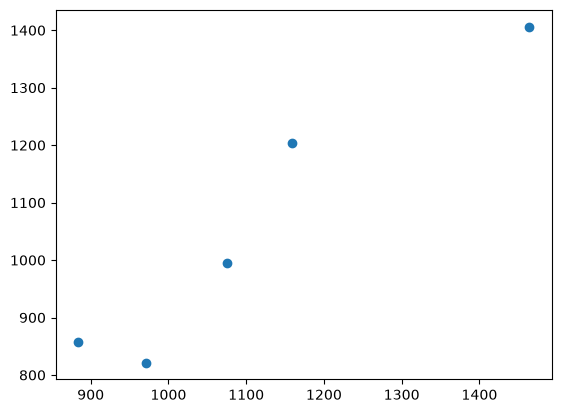

In [54]:
plt.scatter(y_test, y_pred)
plt.show()

## whole code in nut shell

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


# 1. Load dataset
df = pd.read_csv("economic_index.csv")


# 2. Understand dataset
print(df.head())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.isnull().sum())


# 3. Remove unnecessary column
df = df.drop("Unnamed: 0", axis=1)


# 4. Select features and target
X = df[["interest_rate", "unemployment_rate"]]
y = df["index_price"]


# 5. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# 6. Create model
model = LinearRegression()


# 7. Train model
model.fit(X_train, y_train)


# 8. Display model parameters
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)


# 9. Make predictions
y_pred = model.predict(X_test)


# 10. Compare actual and predicted
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison)


# 11. Evaluate model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("R2 Score:", r2)


# 12. Predict new data
new_data = pd.DataFrame({
    "interest_rate": [2.5],
    "unemployment_rate": [5.3]
})

prediction = model.predict(new_data)

print("Predicted Index Price:", prediction[0])


# 13. Plot actual vs predicted
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Index Price")
plt.ylabel("Predicted Index Price")
plt.title("Actual vs Predicted Index Price")

plt.show()